# Composição e organização do genoma de *Colletotrichum abscissum* Ca142

**Montagem:** GCA_023376855.1 ·

**Linhagem:** Ca142 ·

**Anotação:** 15.499 genes codificadores de proteína (MAKER)

O caderno `03_estrutura_ca142.ipynb` terminou com uma pista: alguns scaffolds têm GC baixo (30–45%) e poucos genes,
mas a média por scaffold é grosseira demais para localizar essas regiões. Aqui olhamos o genoma **por dentro dos
scaffolds**:

1. Configuração
2. Compartimentos do genoma: quanto é CDS, íntron e região intergênica
3. GC em janelas: o genoma tem regiões ricas em AT?
4. Sinais de RIP nas regiões ricas em AT
5. Paisagem de scaffolds: GC e genes ao longo da sequência
6. Organização dos genes: distâncias e orientação entre vizinhos
7. GC por posição do códon
8. Tabelas salvas
9. Síntese

**Pré-requisito:** ter executado `03_estrutura_ca142.ipynb`, que gera `data/processed/ca142_genes.tsv`.

**Resultado principal:** o genoma da Ca142 tem dois compartimentos. Cerca de 95% dele tem GC em torno de 53% e é
denso em genes. Os outros 5% estão em blocos com GC perto de 23%, quase sem genes e com a assinatura de RIP.

## 1. Configuração

As bibliotecas e o estilo dos gráficos são os mesmos do caderno 03. A tabela de genes vem pronta de
`data/processed/ca142_genes.tsv`; o genoma e as coordenadas das CDS são lidos de novo dos arquivos do NCBI.

In [7]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO

ACCESSION = "GCA_023376855.1"

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_DADOS = RAIZ / "data" / "raw" / "ca142" / "ncbi_dataset" / "data" / ACCESSION
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

ARQ_GENOMA = next(DIR_DADOS.glob(f"{ACCESSION}_*_genomic.fna"))
ARQ_GFF = DIR_DADOS / "genomic.gff"
ARQ_CDS = DIR_DADOS / "cds_from_genomic.fna"
ARQ_GENES = DIR_PROC / "ca142_genes.tsv"
assert ARQ_GENES.exists(), "Rode antes o caderno 03_estrutura_ca142.ipynb (ele gera ca142_genes.tsv)."

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2), "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
})

def salvar(fig, nome):
    fig.savefig(DIR_FIG / f"{nome}.png", bbox_inches="tight")

def fmt(n):
    """Formata inteiros com ponto como separador de milhar."""
    return f"{n:,.0f}".replace(",", ".")

def eixo_log(ax):
    """Eixo x em escala log com rótulos legíveis (1, 2, 5, 10… 1 kb, 2 kb…)."""
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
    def rotulo(v, _):
        if v >= 1e6:
            return f"{v / 1e6:g} Mb"
        if v >= 1e3:
            return f"{v / 1e3:g} kb"
        return f"{v:g}"
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(rotulo))
    ax.xaxis.set_minor_formatter(NullFormatter())

# Genoma: nome do scaffold -> sequência (maiúsculas)
genoma = {reg.id: str(reg.seq).upper() for reg in SeqIO.parse(ARQ_GENOMA, "fasta")}
TOTAL = sum(len(s) for s in genoma.values())

genes = pd.read_csv(ARQ_GENES, sep="\t")
print(f"{len(genoma)} scaffolds, {fmt(TOTAL)} pb, {fmt(len(genes))} genes")

423 scaffolds, 54.001.896 pb, 15.499 genes


## 2. Compartimentos do genoma

Cada base do genoma está em um de três compartimentos:

- **CDS:** dentro de um trecho codificador;
- **íntron:** dentro de um gene, mas fora da CDS;
- **intergênico:** fora de qualquer gene.

(Como a anotação da Ca142 não tem UTRs, "dentro de um gene" quer dizer entre o códon de início e o de parada. As UTRs
reais, que existem mas não estão anotadas, caem aqui no compartimento intergênico.)

Para contar, usamos **máscaras**: para cada scaffold, um vetor de verdadeiro/falso com uma posição por base. Marcamos
como verdadeiras as posições cobertas por genes e, em outro vetor, as cobertas por CDS. As máscaras resolvem sozinhas
o caso de genes sobrepostos: uma base coberta por dois genes é contada uma vez só.

Também transformamos cada sequência em um vetor do `numpy`, para saber rapidamente quais posições são G ou C.

In [8]:
# Coordenadas dos trechos de CDS (colunas 1, 4 e 5 do GFF, nas linhas do tipo CDS)
cds_coord = []
with open(ARQ_GFF) as f:
    for linha in f:
        if linha.startswith("#"):
            continue
        col = linha.split("\t", 5)
        if len(col) > 4 and col[2] == "CDS":
            cds_coord.append((col[0], int(col[3]), int(col[4])))

mascara_gene = {s: np.zeros(len(seq), dtype=bool) for s, seq in genoma.items()}
mascara_cds = {s: np.zeros(len(seq), dtype=bool) for s, seq in genoma.items()}
for g in genes.itertuples():
    mascara_gene[g.seqid][g.inicio - 1:g.fim] = True          # GFF conta a partir de 1; Python, de 0
for seqid, ini, fim in cds_coord:
    mascara_cds[seqid][ini - 1:fim] = True

# Vetores de bases: quais posições são G/C e quais são bases definidas (A, C, G ou T)
eh_gc, eh_base = {}, {}
for s, seq in genoma.items():
    v = np.frombuffer(seq.encode("ascii"), dtype=np.uint8)
    eh_gc[s] = (v == ord("G")) | (v == ord("C"))
    eh_base[s] = eh_gc[s] | (v == ord("A")) | (v == ord("T"))

def resumo_compartimento(mascaras):
    pb = sum(int((m & eh_base[s]).sum()) for s, m in mascaras.items())
    gc = sum(int((m & eh_gc[s]).sum()) for s, m in mascaras.items())
    return pb, gc

compart = {
    "CDS": mascara_cds,
    "íntrons": {s: mascara_gene[s] & ~mascara_cds[s] for s in genoma},
    "intergênico": {s: ~mascara_gene[s] for s in genoma},
}
linhas = []
for nome, mascaras in compart.items():
    pb, gc = resumo_compartimento(mascaras)
    linhas.append({"compartimento": nome, "pb": pb, "GC (%)": round(100 * gc / pb, 1)})
tab_compart = pd.DataFrame(linhas).set_index("compartimento")
tab_compart.insert(1, "% do genoma", (100 * tab_compart["pb"] / tab_compart["pb"].sum()).round(1))
tab_compart

,pb,% do genoma,GC (%)
compartimento,,,
CDS,21573307,39.9,56.1
íntrons,2394818,4.4,48.0
intergênico,30032925,55.6,47.8


**Resultado**

| Compartimento | Tamanho | % do genoma | GC |
|---|---|---|---|
| CDS | 21,6 Mb | 39,9% | 56,1% |
| íntrons | 2,4 Mb | 4,4% | 48,0% |
| intergênico | 30,0 Mb | 55,6% | 47,8% |

- **O genoma é compacto:** 40% das bases são sequência codificadora. Em plantas e animais essa fração costuma ser de
  poucos pontos percentuais.
- **Os íntrons ocupam pouco** (4,4%), porque são poucos e curtos.
- **A CDS tem GC 8 pontos acima do resto.** Íntrons e regiões intergênicas têm praticamente o mesmo GC (48,0% e
  47,8%). O GC mais alto é, portanto, uma propriedade da sequência codificadora, e não dos genes como um todo. A
  seção 7 mostra de onde ele vem: da 3ª posição dos códons.
- O GC do genoma (51,1%) é a média ponderada dos três compartimentos.

A soma dos três (54.001.050 pb) é o total do genoma menos as 846 bases `N`: a conta fecha.

## 3. GC em janelas

Dividimos cada scaffold em **janelas consecutivas de 10 kb** e calculamos, para cada janela:

- o **GC**;
- a **fração codificadora** (quanto da janela é CDS);
- o **número de genes** (contados pelo ponto médio do gene).

Por que 10 kb? A janela precisa ser grande o bastante para conter alguns genes (um gene a cada ~3,5 kb em média) e
pequena o bastante para não misturar regiões diferentes. O último pedaço de cada scaffold entra como janela se tiver
pelo menos 5 kb; pedaços menores e scaffolds com menos de 5 kb ficam de fora.

In [9]:
JANELA = 10_000

linhas = []
for s, seq in genoma.items():
    L = len(seq)
    for i, ini in enumerate(range(0, L, JANELA)):
        fim = min(ini + JANELA, L)
        validas = int(eh_base[s][ini:fim].sum())
        if fim - ini < JANELA // 2 or validas < (fim - ini) // 2:
            continue                                   # pedaço curto demais ou com muitas bases N
        linhas.append({
            "scaffold": s, "indice": i, "inicio": ini + 1, "fim": fim, "tamanho": fim - ini,
            "gc": eh_gc[s][ini:fim].sum() / validas,
            "frac_cds": mascara_cds[s][ini:fim].mean(),
            "frac_gene": mascara_gene[s][ini:fim].mean(),
        })
jan = pd.DataFrame(linhas)

# Genes por janela, pelo ponto médio do gene
genes["indice"] = ((genes["inicio"] + genes["fim"]) // 2 - 1) // JANELA
n_por_janela = genes.groupby(["seqid", "indice"]).size().rename("n_genes")
jan = jan.merge(n_por_janela, left_on=["scaffold", "indice"], right_index=True, how="left")
jan["n_genes"] = jan["n_genes"].fillna(0).astype(int)

print(f"{fmt(len(jan))} janelas, cobrindo {100 * jan['tamanho'].sum() / TOTAL:.1f}% do genoma")
jan["gc"].mul(100).describe().round(1).to_frame("GC das janelas (%)").T

5.390 janelas, cobrindo 98.9% do genoma


,count,mean,std,min,25%,50%,75%,max
GC das janelas (%),5390.0,51.1,6.6,16.7,50.8,52.9,54.2,60.8


**Resultado:** 5.390 janelas cobrem 98,9% do genoma. A metade central das janelas tem GC entre 50,8% e 54,2%, uma
faixa estreita. Mas os extremos vão de **16,7% a 60,8%**, e a média (51,1%) fica abaixo da mediana (52,9%): há uma
cauda de janelas com GC muito baixo.

### 3.1 Distribuição do GC das janelas

Se o genoma fosse homogêneo, o GC das janelas formaria um único pico estreito. Genomas com regiões ricas em AT
mostram uma **cauda à esquerda** ou até um **segundo pico** em GC baixo.

Para separar as janelas atípicas sem escolher um número arbitrário, usamos uma regra estatística: uma janela é
**rica em AT** se o seu GC está mais de **3 desvios abaixo da mediana**. O desvio é estimado de forma robusta, pelo
MAD (*median absolute deviation*, o desvio absoluto mediano), que não é influenciado pelas próprias janelas atípicas
como o desvio padrão seria. Multiplicar o MAD por 1,4826 dá o equivalente a um desvio padrão em dados normais.

Mediana do GC das janelas: 52.9%  ·  desvio robusto: 2.3 pontos
Limiar para 'rica em AT': GC < 45.9%
Janelas ricas em AT: 423 de 5.390 (4.183.904 pb, 7.8% do genoma em janelas)


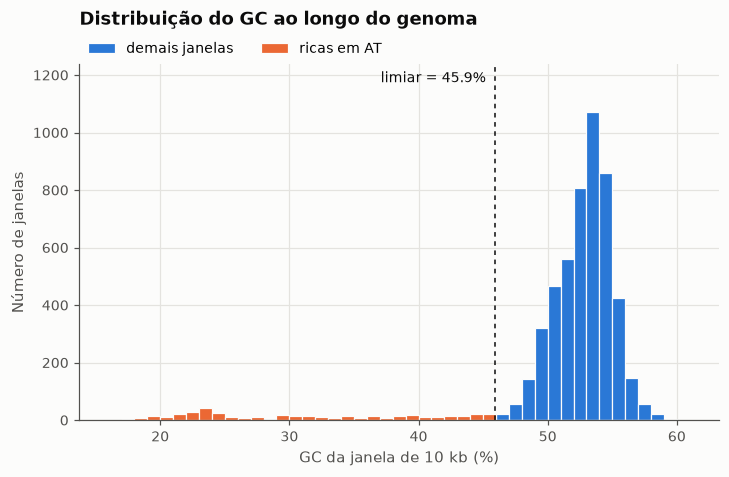

In [10]:
mediana_gc = jan["gc"].median()
desvio_robusto = 1.4826 * (jan["gc"] - mediana_gc).abs().median()
LIMIAR_AT = mediana_gc - 3 * desvio_robusto
jan["rica_at"] = jan["gc"] < LIMIAR_AT

pb_at = jan.loc[jan["rica_at"], "tamanho"].sum()
print(f"Mediana do GC das janelas: {100 * mediana_gc:.1f}%  ·  desvio robusto: {100 * desvio_robusto:.1f} pontos")
print(f"Limiar para 'rica em AT': GC < {100 * LIMIAR_AT:.1f}%")
print(f"Janelas ricas em AT: {fmt(jan['rica_at'].sum())} de {fmt(len(jan))} "
      f"({fmt(pb_at)} pb, {100 * pb_at / jan['tamanho'].sum():.1f}% do genoma em janelas)")

fig, ax = plt.subplots()
bins = np.arange(np.floor(100 * jan["gc"].min()), np.ceil(100 * jan["gc"].max()) + 1, 1)
ax.hist(100 * jan.loc[~jan["rica_at"], "gc"], bins=bins, color=AZUL, edgecolor=FUNDO, linewidth=0.8,
        label="demais janelas")
ax.hist(100 * jan.loc[jan["rica_at"], "gc"], bins=bins, color=LARANJA, edgecolor=FUNDO, linewidth=0.8,
        label="ricas em AT")
ax.set_ylim(top=ax.get_ylim()[1] * 1.1)
ax.axvline(100 * LIMIAR_AT, color=TINTA, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"limiar = {100 * LIMIAR_AT:.1f}%", (100 * LIMIAR_AT, 0.95), xycoords=("data", "axes fraction"),
            xytext=(-6, 0), textcoords="offset points", ha="right", color=TINTA, fontsize=9)
ax.set_xlabel("GC da janela de 10 kb (%)")
ax.set_ylabel("Número de janelas")
ax.set_title("Distribuição do GC ao longo do genoma", pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=2, borderaxespad=0.2)
salvar(fig, "04_gc_janelas")
plt.show()

**Resultado: a distribuição tem dois picos.**

- **Pico principal:** estreito, entre 48% e 58%, com mediana de 52,9% e desvio robusto de 2,3 pontos. Reúne 92% do
  genoma.
- **Segundo pico:** pequeno, em torno de **22–24% de GC**, menos da metade do GC do resto do genoma. Entre os dois
  picos (de 26% a 44%) há poucas janelas, espalhadas.
- **Limiar estatístico:** GC abaixo de 45,9%. Ficam abaixo dele **423 janelas, 4,2 Mb, 7,8% do genoma**.

As janelas ricas em AT são de dois tipos:

| Faixa de GC | Janelas | % do genoma | O que são |
|---|---|---|---|
| menos de 35% | 272 | 5,0% | o **núcleo** do compartimento rico em AT |
| de 35% a 45,9% | 151 | 2,8% | janelas de **transição**, que contêm um pedaço de bloco rico em AT e um pedaço de sequência normal |

A seção 3.2 confirma essa leitura: nas janelas de transição, a fração codificadora é intermediária.

**Conclusão:** o genoma da Ca142 não é homogêneo. Tem regiões com composição muito diferente do resto, que somam
pelo menos 5% das bases. É um limite inferior: sequências repetitivas são as mais difíceis de montar com leituras
curtas, e parte delas pode ter ficado de fora ou colapsada.

**Sobre o limiar:** o vale entre os dois picos fica entre 26% e 44%, e qualquer corte nessa faixa separa o mesmo
núcleo. O limiar de 45,9% é mais sensível e inclui as janelas de transição. Por isso a marca `rica_at` de um gene
deve ser lida como "está perto de um bloco rico em AT", e não como "está dentro de um".

### 3.2 As regiões ricas em AT têm menos genes?

Agrupamos as janelas por faixa de GC e comparamos a fração codificadora e a densidade de genes. É o mesmo teste do
fim do caderno 03, agora na resolução certa.

In [11]:
faixas = [0, 0.35, 0.40, 0.45, 0.50, 0.55, 1]
rotulos = ["< 35%", "35–40%", "40–45%", "45–50%", "50–55%", "≥ 55%"]
jan["faixa_gc"] = pd.cut(jan["gc"], faixas, labels=rotulos, right=False)

por_faixa = jan.groupby("faixa_gc", observed=False).agg(
    janelas=("gc", "size"), pb=("tamanho", "sum"), genes=("n_genes", "sum"),
    cds_media=("frac_cds", "mean"))
por_faixa["% do genoma"] = (100 * por_faixa["pb"] / jan["tamanho"].sum()).round(1)
por_faixa["% codificante"] = (100 * por_faixa["cds_media"]).round(1)
por_faixa["genes por Mb"] = (por_faixa["genes"] / (por_faixa["pb"] / 1e6)).round(0)
por_faixa[["janelas", "% do genoma", "% codificante", "genes por Mb"]]

,janelas,% do genoma,% codificante,genes por Mb
faixa_gc,,,,
< 35%,272,5.0,4.6,45.0
35–40%,59,1.1,22.3,172.0
40–45%,71,1.3,26.3,212.0
45–50%,563,10.4,37.6,313.0
50–55%,3769,70.0,41.5,299.0
≥ 55%,656,12.2,51.3,318.0


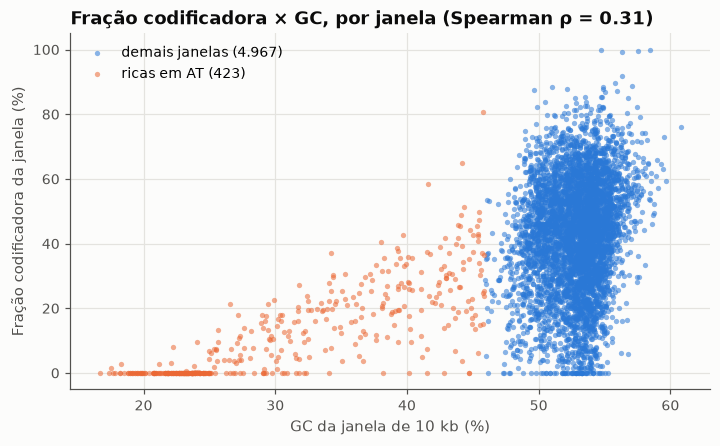

In [12]:
rho = jan["gc"].rank().corr(jan["frac_cds"].rank())      # correlação de Spearman

fig, ax = plt.subplots()
for rica, cor, rotulo in [(False, AZUL, "demais janelas"), (True, LARANJA, "ricas em AT")]:
    sub = jan[jan["rica_at"] == rica]
    ax.scatter(100 * sub["gc"], 100 * sub["frac_cds"], s=12, color=cor, alpha=0.55, linewidth=0,
               label=f"{rotulo} ({fmt(len(sub))})")
ax.set_xlabel("GC da janela de 10 kb (%)")
ax.set_ylabel("Fração codificadora da janela (%)")
ax.set_title(f"Fração codificadora × GC, por janela (Spearman ρ = {rho:.2f})")
ax.legend(loc="upper left")
salvar(fig, "04_cds_gc_janelas")
plt.show()

**Resultado: as regiões ricas em AT são quase vazias de genes.**

- **Abaixo de 35% de GC:** 4,6% de sequência codificadora e 45 genes por Mb. Na faixa principal (50–55%) são 41,5%
  e 299 genes por Mb: **9 vezes menos CDS e 7 vezes menos genes**. Das 272 janelas dessa faixa, 167 não têm nenhuma
  base codificadora.
- **De 35% a 45%:** valores intermediários (22% a 26% de CDS, 172 a 212 genes por Mb), como se espera de janelas que
  misturam os dois compartimentos.
- **Acima de 55%:** as janelas mais densas, com 51% de CDS.
- No conjunto, as janelas ricas em AT têm 12,1% de CDS e 99 genes por Mb, contra 42,4% e 303 nas demais.

**No gráfico**

- À esquerda, uma linha de pontos laranja colada no zero: abaixo de ~26% de GC, as janelas não têm genes.
- No meio (26% a 46%), os pontos sobem em diagonal até encontrar a nuvem azul. É a **linha de mistura**: uma janela
  com metade de bloco rico em AT e metade de sequência normal cai no meio do caminho, em GC e em fração codificadora.
- À direita, a nuvem azul: dentro dela, a fração codificadora vai de 0% a 100% sem relação visível com o GC.

A correlação (ρ = 0,31) é o dobro da calculada por scaffold no caderno 03 (0,15), mas continua moderada, e isso é
informativo: a relação entre GC e genes **não é gradual**. São dois estados, um com genes e outro sem, ligados por
janelas de transição.

## 4. Sinais de RIP

**RIP** (*repeat-induced point mutation*) é um mecanismo de defesa do genoma, exclusivo de fungos: sequências
repetidas (como cópias de transposons) são reconhecidas e recebem mutações de **C para T**. O RIP não troca qualquer
C: ele age de preferência sobre o dinucleotídeo **CpA**, que vira **TpA** (na fita oposta, TpG vira TpA). Com o
tempo, as regiões atingidas ficam ricas em AT e com uma assinatura reconhecível na frequência de dinucleotídeos.

Três índices medem essa assinatura (Margolin et al., 1998; Selker et al., 2003; resumidos em van Wyk et al., 2019,
*PeerJ* 7:e7447, artigo da ferramenta *The RIPper*):

| Índice | Fórmula | O que mede | Indica RIP quando |
|---|---|---|---|
| Produto | TpA / ApT | acúmulo do **produto** do RIP (TpA), em relação a um dinucleotídeo de controle | > 1,1 |
| Substrato | (CpA + TpG) / (ApC + GpT) | esgotamento do **alvo** do RIP (CpA e TpG) | < 0,9 |
| Composto | produto − substrato | os dois efeitos juntos | > 0 |

Calculamos os índices em **janelas de 1 kb** e consideramos uma janela **compatível com RIP** quando os três critérios
são atendidos ao mesmo tempo (os valores de corte são os padrões do *The RIPper*).

**Limite do método:** os índices mostram que a composição da sequência é a que o RIP produz. Não provam que o RIP
ocorreu, nem que o mecanismo está ativo hoje. A confirmação pede a anotação das sequências repetidas e a comparação
entre cópias, uma análise para a etapa seguinte do projeto.

In [13]:
JANELA_RIP = 1_000

def indices_rip(s):
    """Índices de RIP de uma sequência: produto, substrato e composto."""
    ta, at = s.count("TA"), s.count("AT")
    ca, tg, ac, gt = s.count("CA"), s.count("TG"), s.count("AC"), s.count("GT")
    produto = ta / at if at else np.nan
    substrato = (ca + tg) / (ac + gt) if (ac + gt) else np.nan
    return produto, substrato, produto - substrato

linhas = []
for s, seq in genoma.items():
    for ini in range(0, len(seq) - JANELA_RIP + 1, JANELA_RIP):
        trecho = seq[ini:ini + JANELA_RIP]
        if trecho.count("N") > JANELA_RIP // 10:
            continue
        produto, substrato, composto = indices_rip(trecho)
        linhas.append({"scaffold": s, "inicio": ini + 1, "fim": ini + JANELA_RIP,
                       "gc": (trecho.count("G") + trecho.count("C")) / (JANELA_RIP - trecho.count("N")),
                       "produto": produto, "substrato": substrato, "composto": composto,
                       "frac_cds": mascara_cds[s][ini:ini + JANELA_RIP].mean()})
rip = pd.DataFrame(linhas)
rip["rip"] = (rip["produto"] > 1.1) & (rip["substrato"] < 0.9) & (rip["composto"] > 0)

print(f"{fmt(len(rip))} janelas de 1 kb")
print(f"Compatíveis com RIP: {fmt(rip['rip'].sum())} ({100 * rip['rip'].mean():.2f}% do genoma em janelas)")
rip[["produto", "substrato", "composto"]].describe().loc[["25%", "50%", "75%"]].round(2)

53.795 janelas de 1 kb
Compatíveis com RIP: 3.377 (6.28% do genoma em janelas)


,produto,substrato,composto
25%,0.57,1.1,-0.71
50%,0.67,1.2,-0.54
75%,0.79,1.3,-0.34


**Resultado**

- **O genoma "normal" está longe dos critérios de RIP.** Na janela típica, o índice de produto é 0,67 (TpA é um
  dinucleotídeo naturalmente raro), o de substrato é 1,2 e o composto é −0,54. A metade central das janelas tem
  composto entre −0,71 e −0,34.
- **3.377 das 53.795 janelas de 1 kb (6,3%) atendem aos três critérios ao mesmo tempo.**

Nessas janelas os índices são extremos: produto mediano de 1,53 e substrato mediano de **0,07**. Os dinucleotídeos
CpA e TpG, alvos do RIP, quase desapareceram. Isso não é efeito só da riqueza em AT: em uma sequência rica em AT sem
viés de dinucleotídeos, os dois índices ficariam perto de 1.

### 4.1 A assinatura de RIP está nas regiões ricas em AT?

Se as regiões ricas em AT forem produto de RIP, as janelas compatíveis com RIP devem se concentrar nelas e ficar
fora das regiões codificadoras. A célula abaixo mostra três coisas:

1. a porcentagem de janelas de 1 kb com RIP **dentro** e **fora** das janelas de 10 kb ricas em AT da seção 3.1;
2. a mesma porcentagem por faixa de GC da própria janela de 1 kb (tabela e gráfico);
3. a fração codificadora das janelas com e sem RIP.

,janelas_1kb,com_rip,composto_mediano,% com RIP
rica_at,,,,
nas demais janelas de 10 kb,49168,395,-0.56,0.8
em janelas de 10 kb ricas em AT,4176,2953,1.39,70.7


,janelas,com_rip,composto_mediano,% com RIP
faixa_gc,,,,
< 35%,3045,3038,1.47,99.8
35–40%,159,126,0.57,79.2
40–45%,776,70,-0.39,9.0
45–50%,10297,35,-0.54,0.3
50–55%,25568,49,-0.57,0.2
≥ 55%,13950,59,-0.56,0.4


,% codificante (média)
rip,
demais janelas,42.6
janelas compatíveis com RIP,1.8


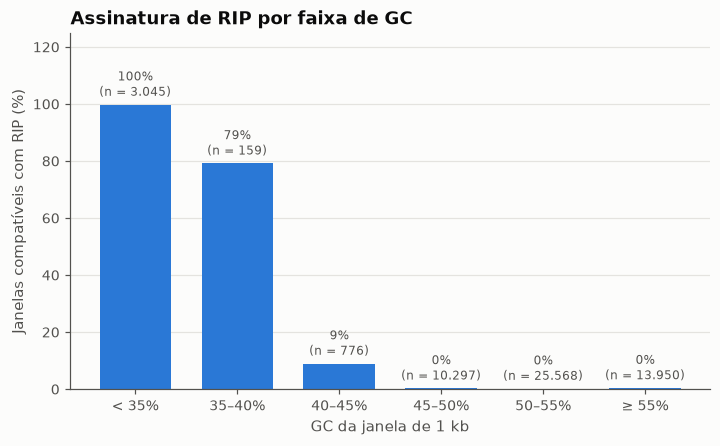

In [14]:
# Cada janela de 1 kb herda a classificação da janela de 10 kb em que está (seção 3.1)
rip["indice"] = (rip["inicio"] - 1) // JANELA
rip = rip.drop(columns="rica_at", errors="ignore").merge(
    jan[["scaffold", "indice", "rica_at"]], on=["scaffold", "indice"], how="left")
rip_regiao = rip.dropna(subset=["rica_at"]).groupby("rica_at").agg(
    janelas_1kb=("rip", "size"), com_rip=("rip", "sum"), composto_mediano=("composto", "median"))
rip_regiao.index = rip_regiao.index.map({True: "em janelas de 10 kb ricas em AT", False: "nas demais janelas de 10 kb"})
rip_regiao["% com RIP"] = (100 * rip_regiao["com_rip"] / rip_regiao["janelas_1kb"]).round(1)
rip_regiao["composto_mediano"] = rip_regiao["composto_mediano"].round(2)
display(rip_regiao)

rip["faixa_gc"] = pd.cut(rip["gc"], faixas, labels=rotulos, right=False)
rip_faixa = rip.groupby("faixa_gc", observed=False).agg(
    janelas=("rip", "size"), com_rip=("rip", "sum"), composto_mediano=("composto", "median"))
rip_faixa["% com RIP"] = (100 * rip_faixa["com_rip"] / rip_faixa["janelas"]).round(1)
rip_faixa["composto_mediano"] = rip_faixa["composto_mediano"].round(2)
display(rip_faixa)

cds_rip = rip.groupby("rip")["frac_cds"].mean().mul(100).round(1)
cds_rip.index = cds_rip.index.map({True: "janelas compatíveis com RIP", False: "demais janelas"})
display(cds_rip.to_frame("% codificante (média)"))

fig, ax = plt.subplots()
valores = rip_faixa["% com RIP"].fillna(0)
ax.bar(rotulos, valores, color=AZUL, width=0.7)
for x, (v, n) in enumerate(zip(valores, rip_faixa["janelas"])):
    ax.annotate(f"{v:.0f}%\n(n = {fmt(n)})", (x, v), xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", color=TINTA_2, fontsize=8)
ax.set_ylim(0, max(valores.max() * 1.25, 5))
ax.set_xlabel("GC da janela de 1 kb")
ax.set_ylabel("Janelas compatíveis com RIP (%)")
ax.set_title("Assinatura de RIP por faixa de GC")
ax.grid(axis="x", visible=False)
salvar(fig, "04_rip_por_gc")
plt.show()

**Resultado: o compartimento rico em AT é o compartimento com assinatura de RIP.**

- **Dentro das janelas de 10 kb ricas em AT, 70,7% das janelas de 1 kb têm a assinatura**, com índice composto
  mediano de +1,39. Fora delas, só 0,8%, com composto de −0,56.
- **Por faixa de GC, a separação é quase total:**
  - abaixo de 35%: **99,8%** (3.038 de 3.045 janelas);
  - de 35% a 40%: 79%;
  - de 40% a 45%: 9%;
  - acima de 45%: entre 0,2% e 0,4%. São 143 janelas em quase 50 mil, o nível de fundo do método.
- **90% das janelas com assinatura de RIP têm GC abaixo de 35%.**
- **Elas não têm genes:** 1,8% de sequência codificadora, contra 42,6% nas demais.

Em outras palavras, praticamente toda janela muito rica em AT deste genoma tem a composição que o RIP produz. A
explicação mais simples é que essas regiões são sequências repetidas (restos de transposons, por exemplo) que
sofreram RIP até perder quase todo o CpA e o TpG.

Vale lembrar o limite do método: os índices mostram a composição, não o mecanismo. A confirmação pede a anotação das
repetições e a comparação entre cópias.

### 4.2 Blocos com assinatura de RIP

Janelas isoladas podem atender aos critérios por acaso. Mais convincentes são os **blocos**: trechos em que várias
janelas consecutivas têm a assinatura. Aqui, um bloco tem pelo menos 4 janelas seguidas (4 kb ou mais) no mesmo
scaffold.

In [15]:
MIN_JANELAS = 4

blocos = []
for s, sub in rip.groupby("scaffold", sort=False):
    sub = sub.sort_values("inicio")
    # um novo grupo começa quando o valor de "rip" muda ou quando há um salto entre janelas
    muda = (sub["rip"] != sub["rip"].shift()) | (sub["inicio"] != sub["fim"].shift() + 1)
    for _, grupo in sub.groupby(muda.cumsum()):
        if grupo["rip"].iloc[0] and len(grupo) >= MIN_JANELAS:
            blocos.append({"scaffold": s, "inicio": int(grupo["inicio"].iloc[0]), "fim": int(grupo["fim"].iloc[-1]),
                           "tamanho": int(grupo["fim"].iloc[-1] - grupo["inicio"].iloc[0] + 1),
                           "gc": grupo["gc"].mean(), "composto": grupo["composto"].mean()})
blocos = pd.DataFrame(blocos, columns=["scaffold", "inicio", "fim", "tamanho", "gc", "composto"])

if len(blocos):
    print(f"{len(blocos)} blocos em {blocos['scaffold'].nunique()} scaffolds, somando {fmt(blocos['tamanho'].sum())} pb "
          f"({100 * blocos['tamanho'].sum() / TOTAL:.2f}% do genoma)")
    display(blocos.nlargest(10, "tamanho").assign(gc=lambda t: (100 * t["gc"]).round(1),
                                                    composto=lambda t: t["composto"].round(2)))
else:
    print("Nenhum bloco com 4 ou mais janelas consecutivas compatíveis com RIP.")

# Genes que tocam um bloco (têm pelo menos uma base dentro dele)
genes["em_bloco_rip"] = False
for b in blocos.itertuples():
    toca = (genes["seqid"] == b.scaffold) & (genes["inicio"] <= b.fim) & (genes["fim"] >= b.inicio)
    genes.loc[toca, "em_bloco_rip"] = True
print(f"Genes que tocam um bloco com assinatura de RIP: {fmt(genes['em_bloco_rip'].sum())}")

196 blocos em 107 scaffolds, somando 2.963.000 pb (5.49% do genoma)


,scaffold,inicio,fim,tamanho,gc,composto
110,SDAQ01000054.1,144001,233000,89000,23.9,1.44
28,SDAQ01000007.1,631001,719000,88000,22.8,1.46
9,SDAQ01000002.1,65001,147000,82000,23.7,1.46
143,SDAQ01000086.1,49001,125000,76000,22.9,1.43
50,SDAQ01000015.1,59001,134000,75000,22.7,1.46
156,SDAQ01000104.1,1,75000,75000,21.8,1.39
144,SDAQ01000087.1,30001,100000,70000,23.4,1.45
102,SDAQ01000048.1,9001,78000,69000,23.3,1.48
63,SDAQ01000021.1,180001,248000,68000,22.9,1.46
85,SDAQ01000032.1,298001,364000,66000,22.7,1.42


Genes que tocam um bloco com assinatura de RIP: 55


**Resultado**

- **196 blocos em 107 scaffolds, somando 2,96 Mb (5,5% do genoma).**
- **As janelas com RIP não estão isoladas:** 88% delas (2.963 de 3.377) fazem parte de um bloco de 4 kb ou mais.
- **Tamanho:** a mediana é de 9 kb, mas 32 blocos têm 20 kb ou mais e 13 têm 50 kb ou mais. O maior tem **89 kb**
  (`SDAQ01000054.1`).
- **Composição uniforme:** os 10 maiores blocos têm GC entre 21,8% e 23,9% e índice composto entre 1,39 e 1,48.
  Blocos de scaffolds diferentes têm quase a mesma composição, como se espera de um mesmo processo agindo sobre todos.
- **55 genes tocam um bloco.** O caderno 06 mostra que são genes atípicos: GC3 mais baixo, proteínas menores e quase
  nenhum conservado.

**Onde os blocos estão**

- 38 dos 196 blocos encostam em uma ponta de scaffold; os outros 158 (81%) estão no interior. A montagem conseguiu
  atravessar a maior parte dessas regiões.
- Há um enriquecimento modesto nas pontas: nos scaffolds de 50 kb ou mais, 10% das janelas de 1 kb das extremidades
  têm assinatura de RIP, contra 6% no conjunto. É o esperado quando a montagem para dentro de uma região repetitiva,
  mas o efeito é pequeno.
- O primeiro bloco da lista é o início do maior scaffold (`SDAQ01000001.1`, posições 1 a 11.000). O caderno 02
  mostrou que esse scaffold começa com a repetição telomérica: o bloco é uma **região subtelomérica**.

Os blocos estão em `ca142_blocos_rip.tsv`, e os genes que os tocam ficam marcados na coluna `em_bloco_rip` da tabela
de contexto (seção 8).

## 5. Paisagem de scaffolds

Números gerais não mostram **onde** as coisas estão. A função `paisagem` desenha, para um scaffold, dois painéis
alinhados pela posição:

- em cima, o **GC** de cada janela de 10 kb, com a mediana do genoma como referência (linha tracejada) e a mesma
  escala vertical em todos os scaffolds;
- embaixo, a **fração codificadora** da mesma janela.

As janelas ricas em AT (seção 3.1) aparecem com uma faixa laranja ao fundo. São dois painéis com eixos próprios, e
não um gráfico com dois eixos verticais, porque as duas medidas têm escalas diferentes.

Mostramos dois scaffolds: o **maior** e, entre os de pelo menos 100 kb, o de **GC mais baixo**. Para ver qualquer
outro, chame `paisagem("SDAQ01000005.1")` com o nome desejado.

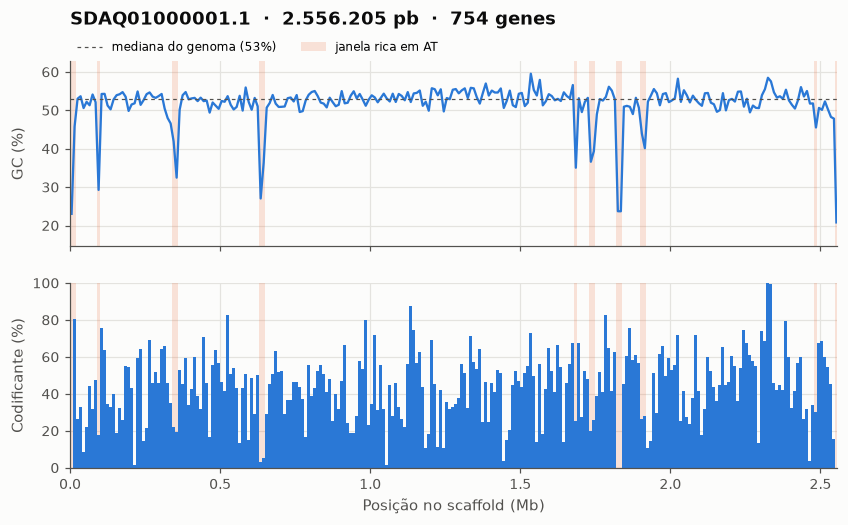

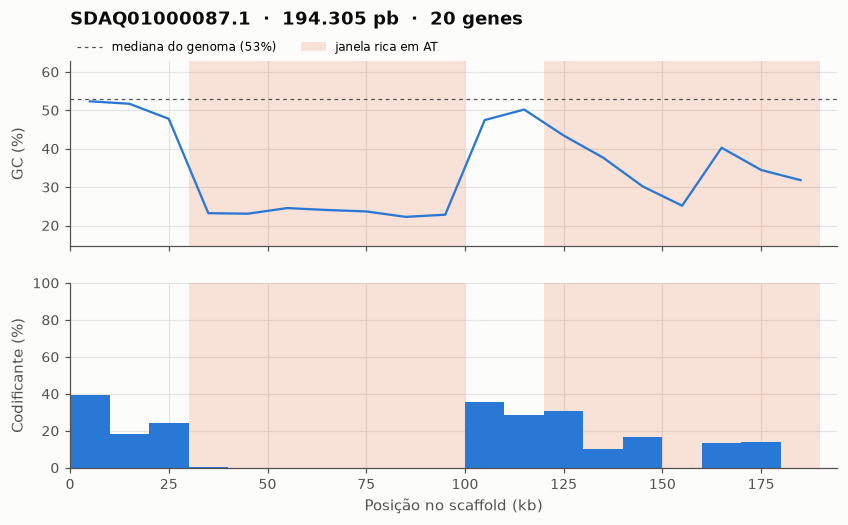

In [16]:
def paisagem(scaffold, salvar_como=None):
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    sub = jan[jan["scaffold"] == scaffold].sort_values("inicio")
    if sub.empty:
        print(f"{scaffold}: sem janelas (scaffold com menos de {JANELA // 2} pb?)")
        return
    L = len(genoma[scaffold])
    escala, unidade = (1e6, "Mb") if L >= 1e6 else (1e3, "kb")
    meio = (sub["inicio"] + sub["fim"]) / 2 / escala

    fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 4.8))
    for ax in (ax1, ax2):
        for w in sub[sub["rica_at"]].itertuples():
            ax.axvspan((w.inicio - 1) / escala, w.fim / escala, color=LARANJA, alpha=0.18, linewidth=0)
    ax1.plot(meio, 100 * sub["gc"], color=AZUL, linewidth=1.5)
    ax1.axhline(100 * mediana_gc, color=TINTA_2, linewidth=0.8, linestyle=(0, (3, 3)))
    # mesma escala de GC em todos os scaffolds, para as paisagens serem comparáveis
    ax1.set_ylim(100 * jan["gc"].min() - 2, 100 * jan["gc"].max() + 2)
    ax1.set_ylabel("GC (%)")
    ax2.bar((sub["inicio"] - 1) / escala, 100 * sub["frac_cds"], width=sub["tamanho"] / escala, align="edge",
            color=AZUL, linewidth=0)
    ax2.set_ylabel("Codificante (%)")
    ax2.set_ylim(0, 100)
    ax2.set_xlim(0, L / escala)
    ax2.set_xlabel(f"Posição no scaffold ({unidade})")
    n_genes = int((genes["seqid"] == scaffold).sum())
    ax1.set_title(f"{scaffold}  ·  {fmt(L)} pb  ·  {fmt(n_genes)} genes", pad=24)
    ax1.legend(handles=[Line2D([], [], color=TINTA_2, linewidth=0.8, linestyle=(0, (3, 3)),
                               label=f"mediana do genoma ({100 * mediana_gc:.0f}%)"),
                        Patch(facecolor=LARANJA, alpha=0.18, label="janela rica em AT")],
               loc="lower left", bbox_to_anchor=(0, 1), ncols=2, fontsize=8, borderaxespad=0.2)
    fig.align_ylabels()
    if salvar_como:
        salvar(fig, salvar_como)
    plt.show()

tam = pd.Series({s: len(seq) for s, seq in genoma.items()})
maior = tam.idxmax()
gc_scaf = (jan["gc"] * jan["tamanho"]).groupby(jan["scaffold"]).sum() / jan.groupby("scaffold")["tamanho"].sum()
candidatos = gc_scaf[tam[gc_scaf.index] >= 100_000]
mais_at = candidatos.idxmin() if len(candidatos) else gc_scaf.idxmin()

paisagem(maior, "04_paisagem_maior_scaffold")
paisagem(mais_at, "04_paisagem_scaffold_rico_em_at")

**Resultado**

**`SDAQ01000001.1`, o maior scaffold (2,56 Mb, 754 genes)**

- O GC fica estável em torno de 53% por quase toda a extensão, com cerca de dez **vales estreitos e profundos**, que
  descem a valores entre 21% e 40%. São 16 janelas ricas em AT e 9 blocos com assinatura de RIP, que somam 88 kb (3,4% do scaffold).
- Cada vale de GC coincide com uma queda da fração codificadora a quase zero. O mais largo, perto de 1,83 Mb, tem
  20 kb quase sem sequência codificadora.
- **As duas pontas do scaffold são ricas em AT.** A inicial é a região subtelomérica já comentada. A final também
  termina em um bloco com RIP (posições 2.550.001 a 2.556.000), o que sugere que o scaffold pode ir de um telômero
  ao outro. Para confirmar, basta procurar a repetição `TTAGGG` nas últimas bases da sequência.
- O GC médio do scaffold é 51,8%, um valor comum. A média escondia tudo isso, como previsto no caderno 03.

**`SDAQ01000087.1`, o scaffold de GC mais baixo entre os de 100 kb ou mais (194 kb, 20 genes)**

- 14 das 19 janelas são ricas em AT. Um bloco contínuo de 70 kb (posições 30 a 100 kb) tem GC de 23% e nenhuma base
  codificadora.
- Os 20 genes estão no começo do scaffold e no trecho entre 100 e 130 kb, onde o GC volta ao normal. A segunda
  metade alterna blocos com RIP e trechos com poucos genes.
- É um dos scaffolds de GC baixo e poucos genes que apareceram no caderno 03: GC médio de 34,5% e 103 genes por Mb.

**Conclusão:** as regiões ricas em AT não são scaffolds à parte. São blocos de 4 a 89 kb **intercalados** na
sequência normal, com bordas nítidas, em scaffolds de todos os tamanhos.

## 6. Organização dos genes

### 6.1 Distância entre genes vizinhos

Para cada par de genes vizinhos no mesmo scaffold, medimos o espaço entre o fim de um e o início do seguinte. Como a
anotação não tem UTRs, essa distância vai de códon de parada/início a códon de início/parada: ela inclui as UTRs e
os promotores reais. Distância negativa significa que os dois modelos de genes se **sobrepõem**.

Pares de genes vizinhos: 15.114
  sobrepostos: 50 (0.3%)
  distância entre os demais: mediana de 1.102 pb (metade entre 608 e 2.114 pb)
  pares a menos de 500 pb: 18.9%  ·  a mais de 10 kb: 1.4%


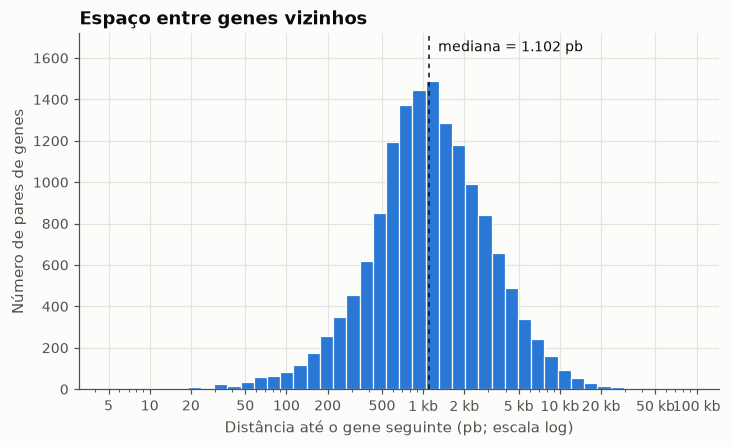

In [17]:
g = genes.sort_values(["seqid", "inicio"]).reset_index(drop=True)
prox = g.groupby("seqid")[["inicio", "fita", "locus_tag"]].shift(-1)

pares = pd.DataFrame({
    "seqid": g["seqid"], "gene_a": g["locus_tag"], "gene_b": prox["locus_tag"],
    "fita_a": g["fita"], "fita_b": prox["fita"],
    "distancia": prox["inicio"] - g["fim"] - 1,
}).dropna(subset=["gene_b"])
pares["distancia"] = pares["distancia"].astype(int)

sobrepostos = pares[pares["distancia"] < 0]
separados = pares[pares["distancia"] >= 0]
print(f"Pares de genes vizinhos: {fmt(len(pares))}")
print(f"  sobrepostos: {fmt(len(sobrepostos))} ({100 * len(sobrepostos) / len(pares):.1f}%)")
q = separados["distancia"].quantile([0.25, 0.5, 0.75])
print(f"  distância entre os demais: mediana de {fmt(q[0.5])} pb (metade entre {fmt(q[0.25])} e {fmt(q[0.75])} pb)")
print(f"  pares a menos de 500 pb: {100 * (separados['distancia'] < 500).mean():.1f}%  ·  "
      f"a mais de 10 kb: {100 * (separados['distancia'] > 10_000).mean():.1f}%")

fig, ax = plt.subplots()
d = separados.loc[separados["distancia"] > 0, "distancia"]
ax.hist(d, bins=np.logspace(np.log10(d.min()), np.log10(d.max()), 45), color=AZUL, edgecolor=FUNDO, linewidth=0.8)
eixo_log(ax)
ax.set_ylim(top=ax.get_ylim()[1] * 1.1)
ax.axvline(q[0.5], color=TINTA, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"mediana = {fmt(q[0.5])} pb", (q[0.5], 0.95), xycoords=("data", "axes fraction"),
            xytext=(6, 0), textcoords="offset points", color=TINTA, fontsize=9)
ax.set_xlabel("Distância até o gene seguinte (pb; escala log)")
ax.set_ylabel("Número de pares de genes")
ax.set_title("Espaço entre genes vizinhos")
salvar(fig, "04_distancia_intergenica")
plt.show()

**Resultado**

- **15.114 pares de genes vizinhos.** Só 50 (0,3%) se sobrepõem.
- **Distância mediana de 1.102 pb**, com metade dos pares entre 608 e 2.114 pb. No histograma em escala log, a
  distribuição tem um único pico, em torno de 1 kb. É o espaçamento de um genoma compacto: esse intervalo precisa
  conter o fim de um transcrito e o promotor do gene seguinte.
- **18,9% dos pares estão a menos de 500 pb.** Podem ser genes realmente adjacentes, mas também genes partidos em
  dois pela predição. Vale lembrar disso ao examinar um candidato a alvo cujo vizinho está muito perto.
- **1,4% dos pares (cerca de 210) estão a mais de 10 kb.** As maiores distâncias, de 77 a 89 kb, têm o tamanho dos
  maiores blocos com RIP da seção 4.2: são os genes de um lado e do outro de um bloco.

### 6.2 Orientação dos genes vizinhos

Dois genes vizinhos podem estar:

- na **mesma direção** (→ → ou ← ←);
- **divergentes** (← →): transcritos em sentidos opostos, a partir de uma região promotora comum entre eles;
- **convergentes** (→ ←): terminam um de frente para o outro.

Se a orientação fosse ao acaso, esperaríamos 50% na mesma direção, 25% divergentes e 25% convergentes.

In [18]:
def classe_orientacao(a, b):
    if a == b:
        return "mesma direção (→ →)"
    return "divergentes (← →)" if (a, b) == ("-", "+") else "convergentes (→ ←)"

separados = separados.assign(orientacao=[classe_orientacao(a, b) for a, b in zip(separados["fita_a"], separados["fita_b"])])
orient = separados.groupby("orientacao").agg(pares=("distancia", "size"), distancia_mediana=("distancia", "median"))
orient["%"] = (100 * orient["pares"] / orient["pares"].sum()).round(1)
orient["esperado ao acaso (%)"] = orient.index.map(lambda o: 50.0 if o.startswith("mesma") else 25.0)
orient["distancia_mediana"] = orient["distancia_mediana"].round(0).astype(int)
orient[["pares", "%", "esperado ao acaso (%)", "distancia_mediana"]]

,pares,%,esperado ao acaso (%),distancia_mediana
orientacao,,,,
convergentes (→ ←),4215,28.0,25.0,553
divergentes (← →),4237,28.1,25.0,1440
mesma direção (→ →),6612,43.9,50.0,1269


**Resultado: os genes vizinhos alternam de fita mais do que o acaso prevê.**

| Orientação | Observado | Esperado ao acaso | Distância mediana |
|---|---|---|---|
| mesma direção (→ →) | 43,9% | 50% | 1.269 pb |
| divergentes (← →) | 28,1% | 25% | 1.440 pb |
| convergentes (→ ←) | 28,0% | 25% | 553 pb |

- **56,1% dos pares estão em fitas opostas**, contra 50% esperados. Com 15 mil pares, uma diferença de 6 pontos está
  muito além da flutuação do acaso (que seria de cerca de 0,4 ponto).
- Divergentes e convergentes têm quase a mesma frequência **por construção**: ao longo de um scaffold, cada troca de
  fita "para dentro" é seguida por uma "para fora". O número informativo é a soma das duas.
- **As distâncias seguem o padrão biológico esperado.** Os pares convergentes são os mais próximos (553 pb): entre
  eles só há os finais dos dois transcritos. Os divergentes são os mais afastados (1.440 pb): o espaço entre eles
  abriga dois promotores. Esse padrão é um bom sinal de que os modelos de genes fazem sentido.

**O que não dá para concluir:** se o excesso de pares em fitas opostas é uma característica do genoma ou um efeito
da anotação. A comparação com as anotações da IMI 504890 e da LW-VAL-2A responderia: se o mesmo excesso aparecer
nas três, é biologia.

## 7. GC por posição do códon

Cada códon tem três posições, e elas não são equivalentes:

- a **1ª e a 2ª** determinam quase sempre o aminoácido: são as mais limitadas pela função da proteína;
- a **3ª** é a mais livre: muitas trocas ali não mudam o aminoácido (códons sinônimos).

Por isso o GC da 3ª posição, o **GC3**, reflete as preferências do genoma (viés de mutação e de uso de códons) mais
do que a função das proteínas. Calculamos GC1, GC2 e GC3 nos genes completos, sem contar o códon de parada, e o GC3
de cada gene.

,GC (%)
1ª posição (GC1),57.7
2ª posição (GC2),45.3
3ª posição (GC3),65.7
CDS inteira,56.2


,TGA,TAG,TAA
% dos genes,42.6,29.5,27.8


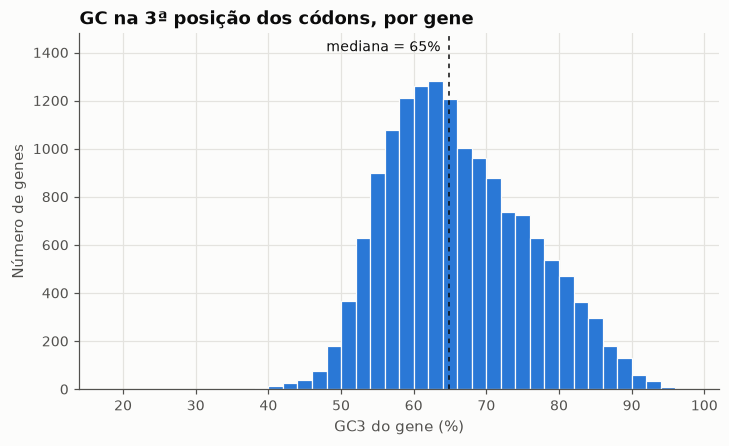

In [19]:
seq_cds = {}
for reg in SeqIO.parse(ARQ_CDS, "fasta"):
    m = re.search(r"\[protein_id=([^\]]+)\]", reg.description)
    if m:
        seq_cds[m.group(1)] = str(reg.seq).upper()

completos = genes[~genes["parcial"]]
soma = np.zeros(3); total = np.zeros(3)
gc3_gene, paradas = {}, Counter()
for g in completos.itertuples():
    s = seq_cds.get(g.protein_id)
    if not s or len(s) % 3:
        continue
    corpo = s[:-3]                                     # sem o códon de parada
    for pos in range(3):
        fatia = corpo[pos::3]                          # todas as bases daquela posição do códon
        gc = fatia.count("G") + fatia.count("C")
        soma[pos] += gc; total[pos] += len(fatia)
        if pos == 2 and fatia:
            gc3_gene[g.locus_tag] = gc / len(fatia)
    paradas[s[-3:]] += 1

genes["gc3"] = genes["locus_tag"].map(gc3_gene)
tab_codon = pd.DataFrame({"GC (%)": (100 * soma / total).round(1)}, index=["1ª posição (GC1)", "2ª posição (GC2)", "3ª posição (GC3)"])
tab_codon.loc["CDS inteira"] = round(100 * soma.sum() / total.sum(), 1)
display(tab_codon)

tab_parada = pd.Series(paradas).sort_values(ascending=False)
display((100 * tab_parada / tab_parada.sum()).round(1).to_frame("% dos genes").T)

fig, ax = plt.subplots()
v = 100 * genes["gc3"].dropna()
ax.hist(v, bins=np.arange(np.floor(v.min()), np.ceil(v.max()) + 2, 2), color=AZUL, edgecolor=FUNDO, linewidth=0.8)
ax.set_ylim(top=ax.get_ylim()[1] * 1.1)
ax.axvline(v.median(), color=TINTA, linewidth=1, linestyle=(0, (3, 3)))
ax.annotate(f"mediana = {v.median():.0f}%", (v.median(), 0.95), xycoords=("data", "axes fraction"),
            xytext=(-6, 0), textcoords="offset points", ha="right", color=TINTA, fontsize=9)
ax.set_xlabel("GC3 do gene (%)")
ax.set_ylabel("Número de genes")
ax.set_title("GC na 3ª posição dos códons, por gene")
salvar(fig, "04_gc3")
plt.show()

**Resultado**

- **GC3 (65,7%) > GC1 (57,7%) > GC2 (45,3%)**, o padrão habitual. O GC3 está 15 pontos acima do GC do genoma
  (51,1%): há uma preferência clara por códons terminados em G ou C. É daí que vem o GC mais alto da CDS (seção 2).
- **Códons de parada:** TGA em 42,6% dos genes, TAG em 29,5% e TAA em 27,8%. O códon mais rico em AT é o menos
  usado, na mesma direção da preferência geral.
- **No histograma**, o GC3 dos genes forma um único pico, com mediana de 65%, e uma cauda longa à direita, até mais
  de 90%. Não há um segundo grupo de genes com GC3 baixo.

**Os genes de GC3 mais baixo** (calculado na revisão, com a tabela `ca142_genes_final.tsv`): só 65 genes têm GC3
abaixo de 45%. Deles, 95% são hipotéticos, e a proteína mediana tem 82 aa. Só 6% estão em janelas ricas em AT. São,
na maioria, predições curtas e sem função conhecida, e não genes degradados por RIP: um GC3 muito abaixo do padrão
do genoma é mais um sinal de modelo duvidoso.

In [20]:
# Contexto de cada gene: a janela de 10 kb em que está o seu ponto médio
contexto = genes.merge(jan[["scaffold", "indice", "gc", "rica_at"]].rename(columns={"scaffold": "seqid", "gc": "gc_janela"}),
                       on=["seqid", "indice"], how="left")
contexto["rica_at"] = contexto["rica_at"].astype("boolean")

comp = contexto[~contexto["parcial"]].groupby("rica_at", dropna=True).agg(
    genes=("locus_tag", "size"), gc3_mediano=("gc3", "median"), proteina_mediana=("tam_proteina", "median"))
comp.index = comp.index.map({True: "em janela rica em AT", False: "nas demais janelas"})
comp["gc3_mediano"] = (100 * comp["gc3_mediano"]).round(1)
comp

,genes,gc3_mediano,proteina_mediana
rica_at,,,
nas demais janelas,14753,65.0,395.0
em janela rica em AT,409,61.5,351.0


**Resultado:** 409 genes completos (2,7%) estão em janelas ricas em AT. O GC3 mediano deles é 61,5%, contra 65,0%
nos demais, e a proteína mediana é menor (351 contra 395 aa).

A diferença existe, mas é pequena: 3,5 pontos de GC3, em janelas cujo GC é dezenas de pontos mais baixo. Os genes
que ficam perto dos blocos ricos em AT **mantêm a composição de genes normais**. A assinatura de RIP está nos blocos
sem genes, e não nos genes vizinhos. O caderno 06 refina essa comparação usando a distância de cada gene ao bloco
mais próximo.

## 8. Tabelas salvas

| Arquivo | Uma linha por | Conteúdo |
|---|---|---|
| `ca142_janelas_10kb.tsv` | janela de 10 kb | GC, fração codificadora, número de genes, se é rica em AT |
| `ca142_janelas_rip_1kb.tsv` | janela de 1 kb | índices de RIP e se é compatível com RIP |
| `ca142_blocos_rip.tsv` | bloco | trechos de 4 kb ou mais com assinatura de RIP |
| `ca142_genes_contexto.tsv` | gene | GC3, GC da janela, região rica em AT, bloco de RIP, distância aos vizinhos |

A tabela de contexto é usada no caderno `06_sintese_ca142.ipynb`.

In [21]:
# Distância de cada gene aos dois vizinhos (vazia para o primeiro e o último gene de cada scaffold)
dist_seg = pares.set_index("gene_a")["distancia"]
dist_ant = pares.set_index("gene_b")["distancia"]
contexto["dist_gene_anterior"] = contexto["locus_tag"].map(dist_ant).astype("Int64")
contexto["dist_gene_seguinte"] = contexto["locus_tag"].map(dist_seg).astype("Int64")

colunas = ["locus_tag", "gc3", "gc_janela", "rica_at", "em_bloco_rip", "dist_gene_anterior", "dist_gene_seguinte"]
saidas = {
    "ca142_janelas_10kb.tsv": jan.drop(columns="indice"),
    "ca142_janelas_rip_1kb.tsv": rip.drop(columns="indice"),
    "ca142_blocos_rip.tsv": blocos,
    "ca142_genes_contexto.tsv": contexto[colunas].round({"gc3": 4, "gc_janela": 4}),
}
for nome, tabela in saidas.items():
    tabela.to_csv(DIR_PROC / nome, sep="\t", index=False)
    print(f"{nome:28s} {fmt(len(tabela)):>7s} linhas")

ca142_janelas_10kb.tsv         5.390 linhas
ca142_janelas_rip_1kb.tsv     53.795 linhas
ca142_blocos_rip.tsv             196 linhas
ca142_genes_contexto.tsv      15.499 linhas


## 9. Síntese

A célula abaixo reúne os principais números deste caderno.

In [22]:
at_com_rip = rip.loc[rip["rica_at"] == True, "rip"]
sintese = pd.Series(dtype="object", data={
    "Genoma em CDS": f"{tab_compart.loc['CDS', '% do genoma']}%",
    "GC: CDS / íntrons / intergênico": " / ".join(f"{v}%" for v in tab_compart["GC (%)"]),
    "GC mediano das janelas de 10 kb": f"{100 * mediana_gc:.1f}%",
    "Limiar de janela rica em AT": f"GC < {100 * LIMIAR_AT:.1f}%",
    "Genoma em janelas ricas em AT": f"{100 * pb_at / jan['tamanho'].sum():.1f}%",
    "Fração codificadora: ricas em AT / demais": f"{100 * jan.loc[jan['rica_at'], 'frac_cds'].mean():.1f}% / "
                                                 f"{100 * jan.loc[~jan['rica_at'], 'frac_cds'].mean():.1f}%",
    "Janelas de 1 kb compatíveis com RIP": f"{100 * rip['rip'].mean():.2f}%",
    "  dentro das janelas ricas em AT": f"{100 * at_com_rip.mean():.1f}%" if len(at_com_rip) else "—",
    "Blocos com RIP (≥ 4 kb)": f"{len(blocos)} ({fmt(blocos['tamanho'].sum())} pb)",
    "Genes que tocam blocos com RIP": fmt(genes["em_bloco_rip"].sum()),
    "Distância mediana entre genes vizinhos": f"{fmt(q[0.5])} pb",
    "Pares de genes sobrepostos": fmt(len(sobrepostos)),
    "GC1 / GC2 / GC3": " / ".join(f"{v}%" for v in tab_codon["GC (%)"].iloc[:3]),
})
sintese.to_frame("Ca142")

,Ca142
Genoma em CDS,39.9%
GC: CDS / íntrons / intergênico,56.1% / 48.0% / 47.8%
GC mediano das janelas de 10 kb,52.9%
Limiar de janela rica em AT,GC < 45.9%
Genoma em janelas ricas em AT,7.8%
Fração codificadora: ricas em AT / demais,12.1% / 42.4%
Janelas de 1 kb compatíveis com RIP,6.28%
dentro das janelas ricas em AT,70.7%
Blocos com RIP (≥ 4 kb),196 (2.963.000 pb)
Genes que tocam blocos com RIP,55


## Conclusões deste caderno

1. **O genoma é compacto.** 40% das bases são CDS, e os genes vizinhos estão a 1,1 kb um do outro (mediana).
2. **Existem regiões ricas em AT.** A distribuição do GC tem dois picos: o principal em 53% e um segundo em 22–24%.
   Pelo menos 5% do genoma está no núcleo desse segundo compartimento, e 7,8% em janelas abaixo do limiar.
3. **Elas são quase vazias de genes.** Abaixo de 35% de GC há 4,6% de CDS e 45 genes por Mb, contra 41,5% e 299 na
   faixa principal.
4. **Elas têm a assinatura de RIP.** 99,8% das janelas de 1 kb com GC abaixo de 35% atendem aos três critérios. São
   196 blocos, de 4 a 89 kb, que somam 2,96 Mb (5,5% do genoma).
5. **Os blocos estão intercalados na sequência normal**, com bordas nítidas, e 81% deles ficam no interior dos
   scaffolds. O maior scaffold começa em um telômero e tem um bloco subtelomérico.
6. **A organização dos genes faz sentido.** Pares convergentes são os mais próximos e divergentes os mais afastados.
   Há um excesso de vizinhos em fitas opostas (56% contra 50%) cuja origem ainda não está clara.
7. **O GC alto da CDS vem da 3ª posição dos códons** (GC3 de 65,7%). Não há um grupo de genes com composição de RIP.

**Para a escolha de alvos de RNAi**

- Os blocos com RIP não têm genes, então quase nenhum candidato cai dentro deles: só 55 genes tocam um bloco.
- Genes **perto** de blocos merecem atenção por outro motivo: em outros fungos, as regiões vizinhas a repetições
  evoluem mais depressa. O caderno 06 mostra que, na Ca142, quanto mais perto de um bloco, menor a proporção de genes
  conservados.

**Limitações**

- A montagem com leituras curtas subestima as regiões repetitivas: os valores dos itens 2 e 4 são limites
  inferiores. A montagem LW-VAL-2A (PacBio) é a mais indicada para medir o tamanho real dessas regiões.
- Os índices de RIP indicam composição compatível, não provam o mecanismo. O passo seguinte seria anotar as
  repetições (RepeatModeler, EDTA) e ver se os blocos correspondem a famílias de transposons.
- Sem UTRs anotadas, as distâncias entre genes estão superestimadas em relação ao espaço realmente não transcrito.

**Próximo caderno:** `05_completude_busco_ca142.ipynb` mede a completude do conjunto de genes.